Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


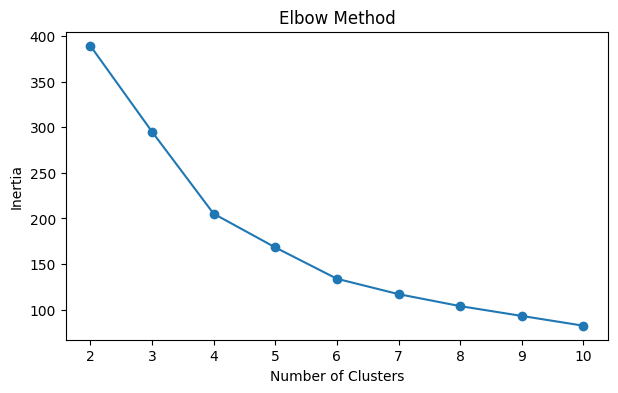

Silhouette Score: 0.417

Customer Segment Profiles:


,Age,Annual Income (k$),Spending Score (1-100),Customer Count
Cluster,,,,
0,46.25,26.75,18.35,20
1,25.19,41.09,62.24,54
2,32.88,86.10,81.53,40
3,39.87,86.10,19.36,39
4,55.64,54.38,48.85,47


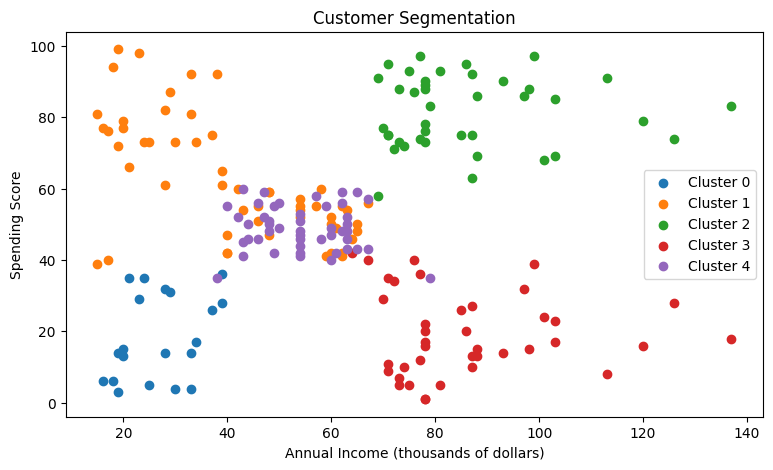


Sample Customers with Assigned Segments:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster,Marketing Strategy
0,1,19,15,39,1,Engagement campaigns and targeted offers
1,2,21,15,81,1,Discounts and budget-friendly products
2,3,20,16,6,0,Engagement campaigns and targeted offers
3,4,23,16,77,1,Discounts and budget-friendly products
4,5,31,17,40,1,Membership benefits and product recommendations
5,6,22,17,76,1,Discounts and budget-friendly products
6,7,35,18,6,0,Engagement campaigns and targeted offers
7,8,23,18,94,1,Discounts and budget-friendly products
8,9,64,19,3,0,Engagement campaigns and targeted offers
9,10,30,19,72,1,Discounts and budget-friendly products


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Load Dataset
url = "https://raw.githubusercontent.com/MahimaSriK/Mall-Customer-Segmentation-Dataset/main/Mall_Customers.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
display(df.head())

# 2. Select Features
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

# 3. Scale Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Find Suitable Number of Clusters using Elbow Method
inertia = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

# 5. Apply K-Means Clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

score = silhouette_score(X_scaled, df["Cluster"])
print("Silhouette Score:", round(score, 3))

# 6. Analyze Customer Segments
profile = df.groupby("Cluster")[features].mean().round(2)
profile["Customer Count"] = df["Cluster"].value_counts().sort_index()

print("\nCustomer Segment Profiles:")
display(profile)

# 7. Visualize Customer Segments
plt.figure(figsize=(9, 5))
for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]
    plt.scatter(
        group["Annual Income (k$)"],
        group["Spending Score (1-100)"],
        label=f"Cluster {cluster}")

plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.legend()
plt.show()

# 8. Create Marketing Recommendations
def marketing_strategy(row):
    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]

    if income >= 70 and spending >= 60:
        return "Premium offers and loyalty rewards"
    elif income >= 70 and spending < 40:
        return "Exclusive deals and personalized promotions"
    elif income < 40 and spending >= 60:
        return "Discounts and budget-friendly products"
    elif spending < 40:
        return "Engagement campaigns and targeted offers"
    else:
        return "Membership benefits and product recommendations"

df["Marketing Strategy"] = df.apply(marketing_strategy, axis=1)

print("\nSample Customers with Assigned Segments:")
display(df[[
    "CustomerID", "Age", "Annual Income (k$)",
    "Spending Score (1-100)", "Cluster", "Marketing Strategy"
]].head(10))